In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv("telecom_churn.csv")
df

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3328,AZ,192,415,No,Yes,36,156.2,77,26.55,215.5,126,18.32,279.1,83,12.56,9.9,6,2.67,2,False
3329,WV,68,415,No,No,0,231.1,57,39.29,153.4,55,13.04,191.3,123,8.61,9.6,4,2.59,3,False
3330,RI,28,510,No,No,0,180.8,109,30.74,288.8,58,24.55,191.9,91,8.64,14.1,6,3.81,2,False
3331,CT,184,510,Yes,No,0,213.8,105,36.35,159.6,84,13.57,139.2,137,6.26,5.0,10,1.35,2,False


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   3333 non-null   str    
 1   Account length          3333 non-null   int64  
 2   Area code               3333 non-null   int64  
 3   International plan      3333 non-null   str    
 4   Voice mail plan         3333 non-null   str    
 5   Number vmail messages   3333 non-null   int64  
 6   Total day minutes       3333 non-null   float64
 7   Total day calls         3333 non-null   int64  
 8   Total day charge        3333 non-null   float64
 9   Total eve minutes       3333 non-null   float64
 10  Total eve calls         3333 non-null   int64  
 11  Total eve charge        3333 non-null   float64
 12  Total night minutes     3333 non-null   float64
 13  Total night calls       3333 non-null   int64  
 14  Total night charge      3333 non-null   float64
 15

In [4]:
df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [5]:
print(df.columns)

Index(['State', 'Account length', 'Area code', 'International plan',
       'Voice mail plan', 'Number vmail messages', 'Total day minutes',
       'Total day calls', 'Total day charge', 'Total eve minutes',
       'Total eve calls', 'Total eve charge', 'Total night minutes',
       'Total night calls', 'Total night charge', 'Total intl minutes',
       'Total intl calls', 'Total intl charge', 'Customer service calls',
       'Churn'],
      dtype='str')


In [6]:
df['Churn'] = df['Churn'].astype('int64[pyarrow]')

In [7]:
df.describe(include=["object","bool"])

/var/folders/mc/sfhtpvd52p98f218ysdxkwy00000gn/T/ipykernel_7484/3403643252.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=["object","bool"])


,State,International plan,Voice mail plan
count,3333,3333,3333
unique,51,2,2
top,WV,No,No
freq,106,3010,2411


In [8]:
df['Churn'].value_counts()

Churn
0    2850
1     483
Name: count, dtype: int64[pyarrow]

In [9]:
df['Churn'].value_counts(normalize=True)

Churn
0    0.855086
1    0.144914
Name: proportion, dtype: double[pyarrow]

In [10]:
df.sort_values(by="Total day charge",ascending=False)

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
365,CO,154,415,No,No,0,350.8,75,59.64,216.5,94,18.40,253.9,100,11.43,10.1,9,2.73,1,1
985,NY,64,415,Yes,No,0,346.8,55,58.96,249.5,79,21.21,275.4,102,12.39,13.3,9,3.59,1,1
2594,OH,115,510,Yes,No,0,345.3,81,58.70,203.4,106,17.29,217.5,107,9.79,11.8,8,3.19,1,1
156,OH,83,415,No,No,0,337.4,120,57.36,227.4,116,19.33,153.9,114,6.93,15.8,7,4.27,0,1
605,MO,112,415,No,No,0,335.5,77,57.04,212.5,109,18.06,265.0,132,11.93,12.7,8,3.43,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1986,WI,70,415,No,No,0,7.9,100,1.34,136.4,83,11.59,156.6,89,7.05,12.1,1,3.27,0,0
2753,OH,134,415,No,No,0,7.8,86,1.33,171.4,100,14.57,186.5,80,8.39,12.9,2,3.48,2,0
2736,OK,127,510,No,Yes,27,2.6,113,0.44,254.0,102,21.59,242.7,156,10.92,9.2,5,2.48,3,0
1397,VT,101,510,No,No,0,0.0,0,0.00,192.1,119,16.33,168.8,95,7.60,7.2,4,1.94,1,0


In [11]:
df['State'].value_counts()

State
WV    106
MN     84
NY     83
AL     80
OH     78
WI     78
OR     78
VA     77
WY     77
CT     74
ID     73
VT     73
MI     73
TX     72
UT     72
IN     71
KS     70
MD     70
NJ     68
MT     68
NC     68
CO     66
WA     66
NV     66
MA     65
RI     65
MS     65
AZ     64
MO     63
FL     63
NM     62
ME     62
ND     62
OK     61
NE     61
DE     61
SC     60
SD     60
KY     59
IL     58
NH     56
AR     55
GA     54
DC     54
HI     53
TN     53
AK     52
LA     51
PA     45
IA     44
CA     34
Name: count, dtype: int64

In [12]:
df['Churn'].value_counts(normalize=True)

Churn
0    0.855086
1    0.144914
Name: proportion, dtype: double[pyarrow]

<Axes: xlabel='Churn', ylabel='count'>

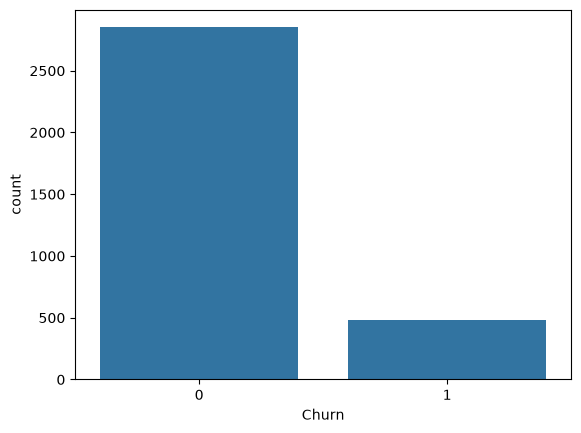

In [13]:
sns.countplot(x="Churn",data=df)

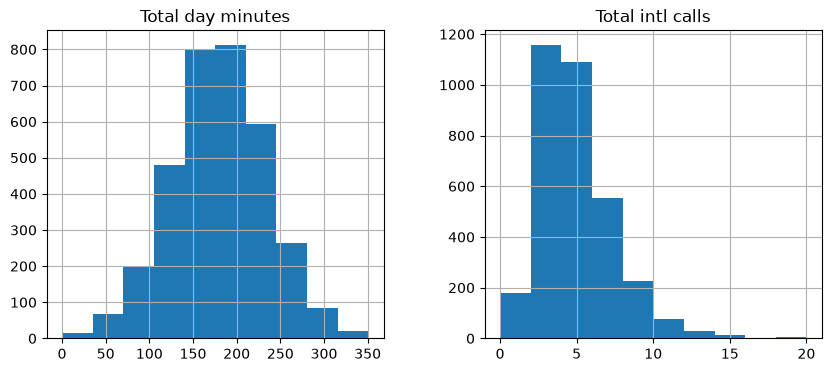

In [14]:
features = ["Total day minutes","Total intl calls"]
df[features].hist(figsize=(10,4));

array([[<Axes: ylabel='Density'>, <Axes: ylabel='Density'>]], dtype=object)

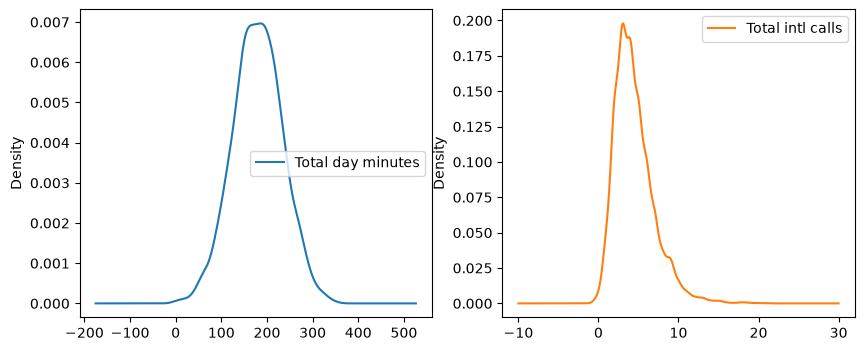

In [15]:
df[features].plot(
    kind='density',subplots=True,sharex=False, layout=(1,2),figsize=(10,4)
)

<Axes: xlabel='Total intl calls', ylabel='Density'>

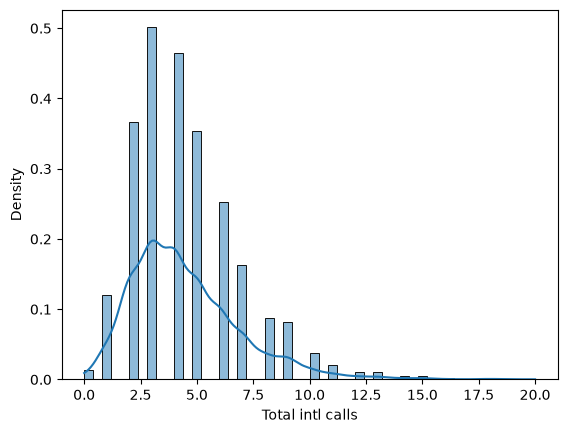

In [16]:
sns.histplot(df["Total intl calls"],kde=True,stat="density")

/var/folders/mc/sfhtpvd52p98f218ysdxkwy00000gn/T/ipykernel_7484/2818465734.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Total intl calls"])


<Axes: xlabel='Total intl calls', ylabel='Density'>

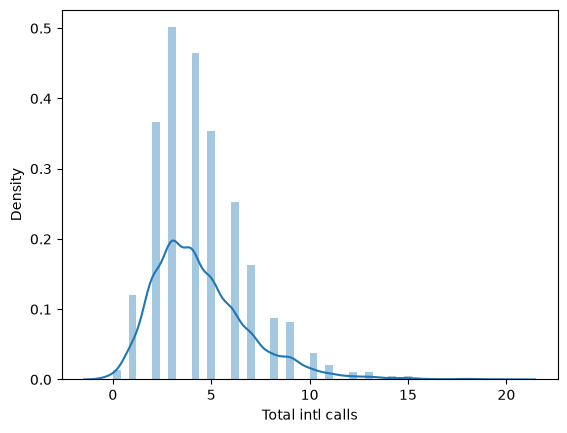

In [17]:
sns.distplot(df["Total intl calls"])

<Axes: xlabel='Total intl calls'>

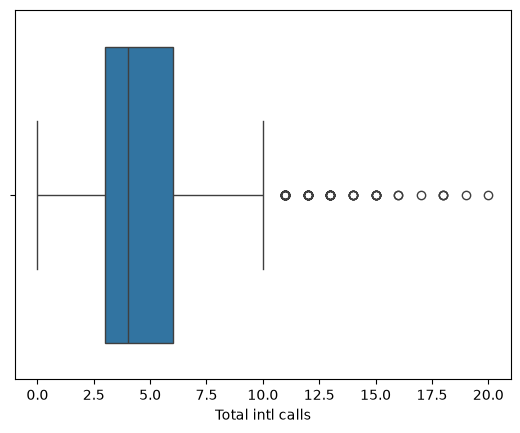

In [18]:
sns.boxplot(x="Total intl calls",data=df)

<Axes: xlabel='Total intl calls'>

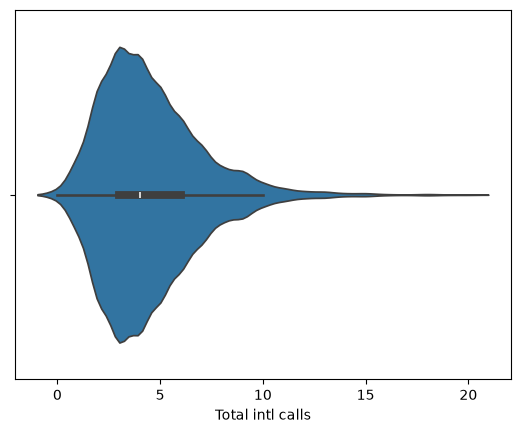

In [19]:
sns.violinplot(x="Total intl calls",data=df)

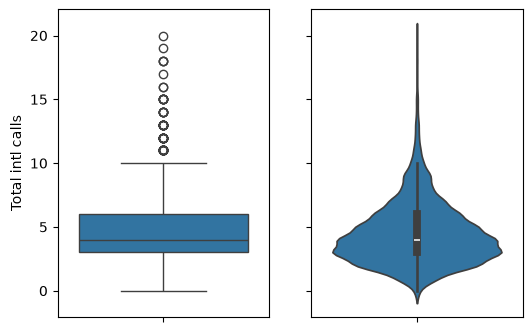

In [20]:
_, axes = plt.subplots(1, 2, sharey=True, figsize=(6, 4))
sns.boxplot(data=df["Total intl calls"], ax=axes[0])
sns.violinplot(data=df["Total intl calls"], ax=axes[1]);

In [21]:
df[features].describe()

,Total day minutes,Total intl calls
count,3333.000000,3333.000000
mean,179.775098,4.479448
std,54.467389,2.461214
min,0.000000,0.000000
25%,143.700000,3.000000
50%,179.400000,4.000000
75%,216.400000,6.000000
max,350.800000,20.000000


<Axes: xlabel='Churn', ylabel='count'>

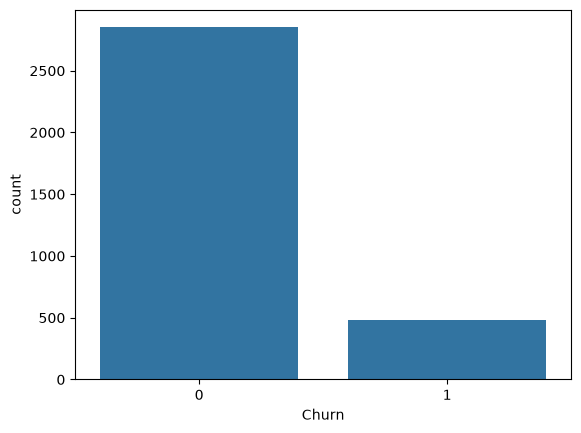

In [22]:
sns.countplot(x='Churn',data=df)

<Axes: xlabel='Customer service calls', ylabel='count'>

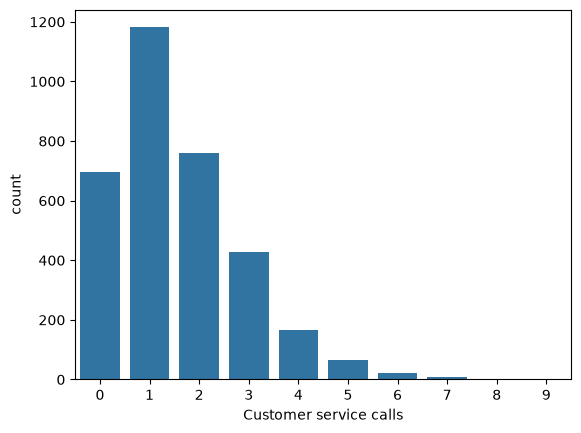

In [23]:
sns.countplot(x="Customer service calls",data=df)

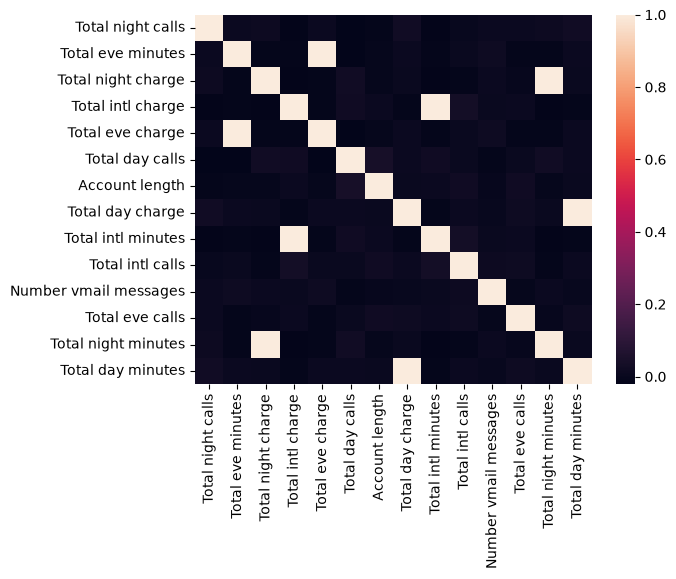

In [24]:
# Drop non-numerical variables
numerical = list(
    set(df.columns)
    - set(
        [
            "State",
            "International plan",
            "Voice mail plan",
            "Area code",
            "Churn",
            "Customer service calls",
        ]
    )
)

# Calculate and plot
corr_matrix = df[numerical].corr()
sns.heatmap(corr_matrix);

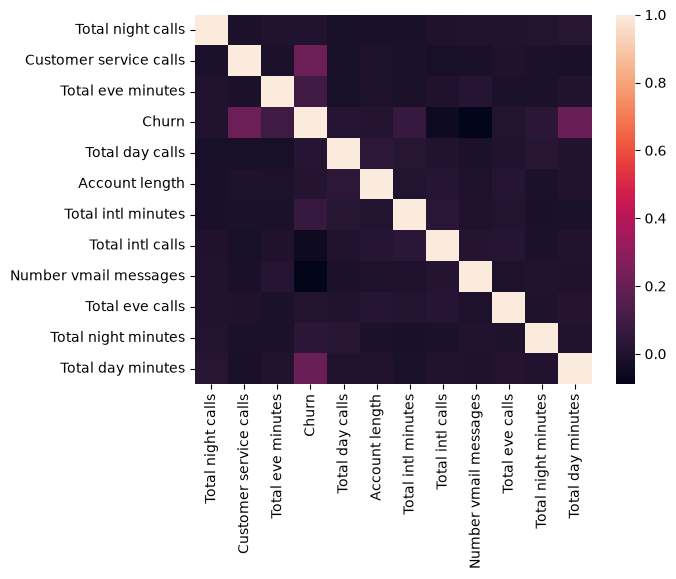

In [25]:
numerical = list(
    set(df.columns)
    - set(
        [
            "State",
            "International plan",
            "Voice mail plan",
            "Area code",
            "churn",
            "Total day charge",
            "Total eve charge",
            "Total night charge",
            "Total intl charge",
            "Customer service call"
        ]
    )
)

corr_matrix = df[numerical].corr()
sns.heatmap(corr_matrix);

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   State                   3333 non-null   str           
 1   Account length          3333 non-null   int64         
 2   Area code               3333 non-null   int64         
 3   International plan      3333 non-null   str           
 4   Voice mail plan         3333 non-null   str           
 5   Number vmail messages   3333 non-null   int64         
 6   Total day minutes       3333 non-null   float64       
 7   Total day calls         3333 non-null   int64         
 8   Total day charge        3333 non-null   float64       
 9   Total eve minutes       3333 non-null   float64       
 10  Total eve calls         3333 non-null   int64         
 11  Total eve charge        3333 non-null   float64       
 12  Total night minutes     3333 non-null   float64       
 13 

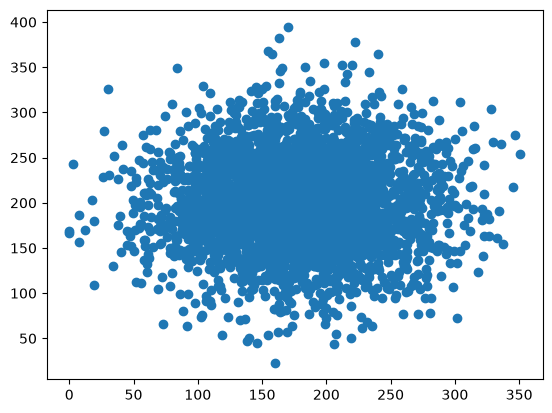

In [27]:
plt.scatter(df["Total day minutes"],df["Total night minutes"])

jointplot lots two histograms that may be useful in some cases.

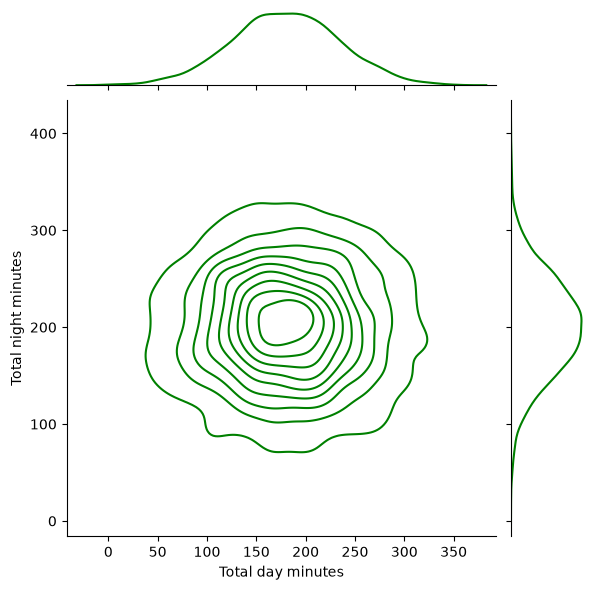

In [28]:
sns.jointplot(
    x="Total day minutes",y="Total night minutes",data=df,kind="kde",color="g"
)

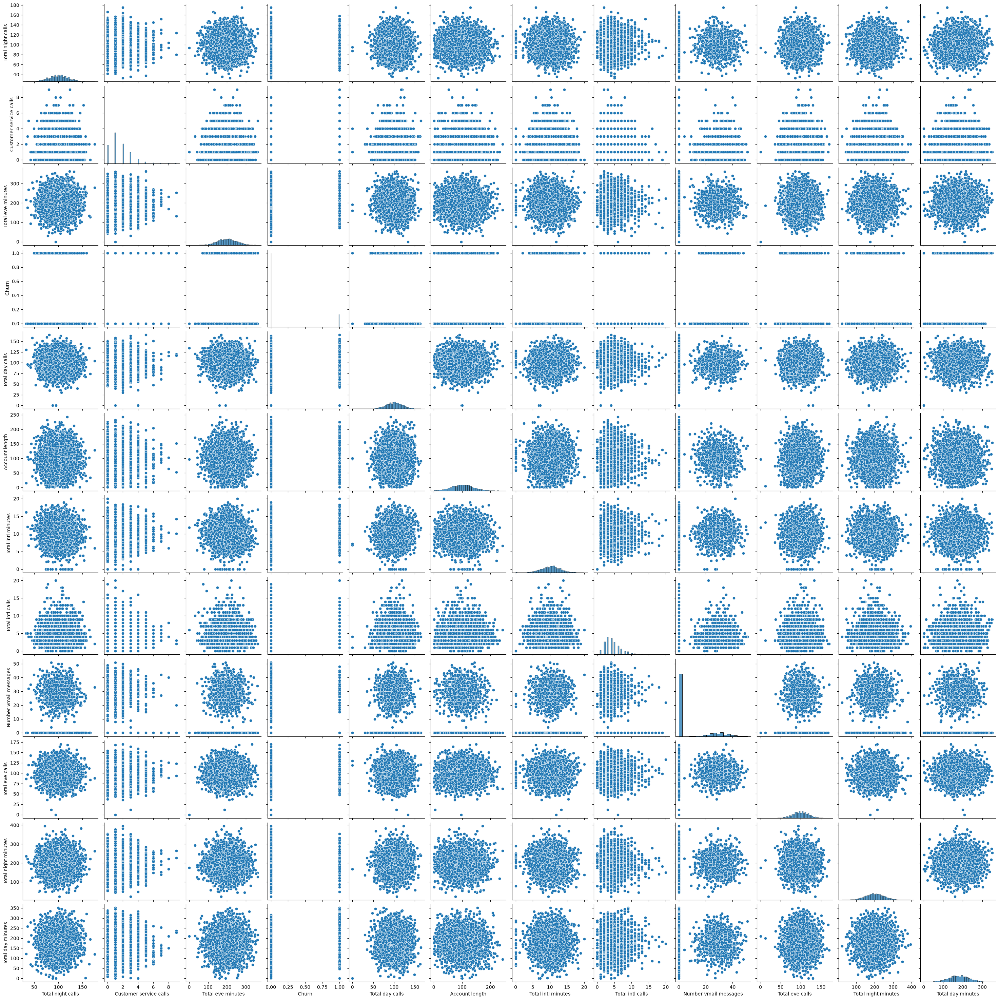

In [29]:
%config InlineBackend.figure_format = "png"
sns.pairplot(df[numerical])

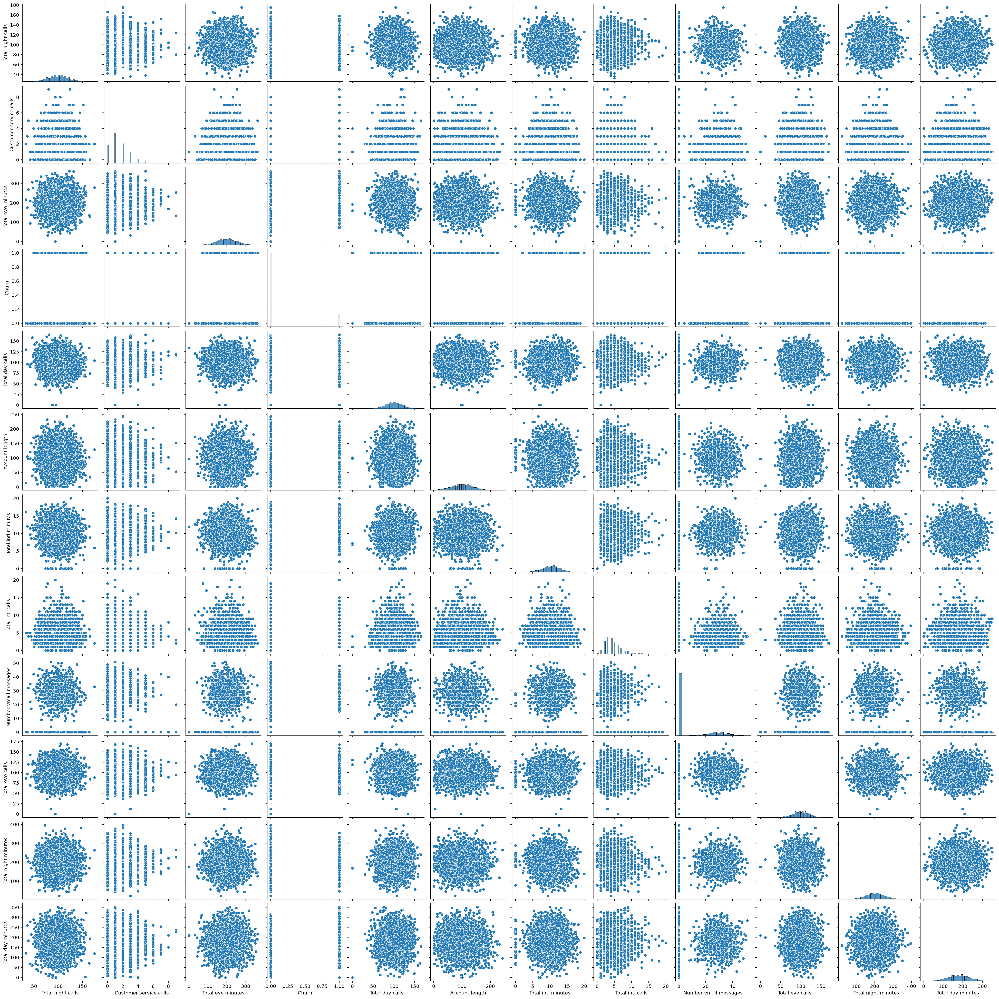

In [30]:
%config InlineBackend.figure_format = "retina"
sns.pairplot(df[numerical])

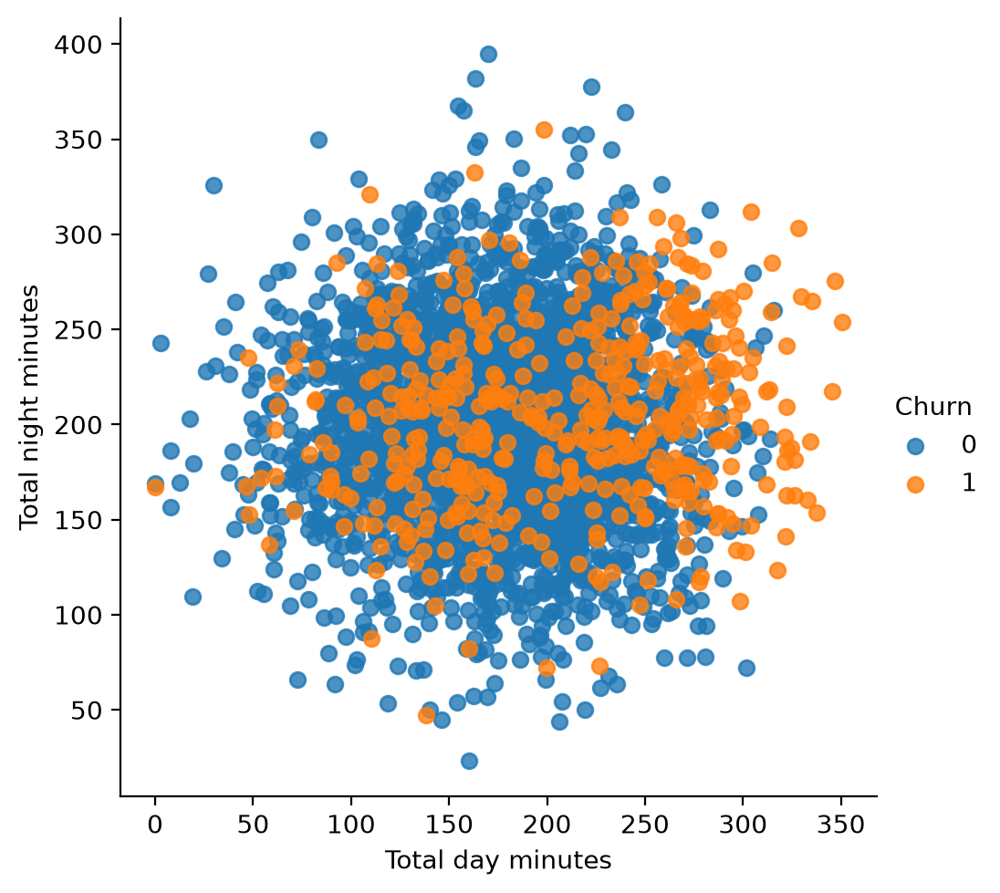

In [31]:
sns.lmplot(x="Total day minutes",y="Total night minutes",data=df,hue="Churn",fit_reg=False)

ValueError: Could not interpret value `feat` for `y`. An entry with this name does not appear in `data`.

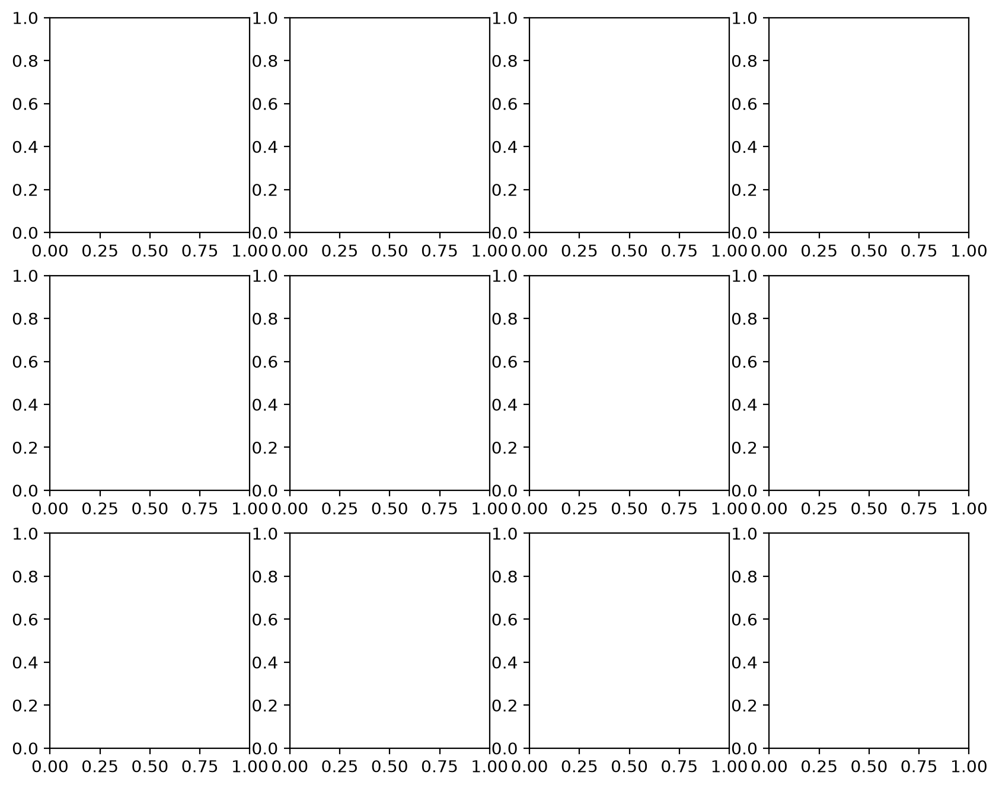

In [34]:
numerical.append("Customer service calls")

fig,axes = plt.subplots(nrows=3,ncols=4,figsize = (10,8))
for idx,feat in enumerate(numerical):
    ax = axes[int(idx/4),idx%4]
    sns.boxplot(x="Churn",y="feat",data=df,ax=ax)
    ax.set_xlable("")
    ax.set_ylable("feat")
fig.tight_layout();

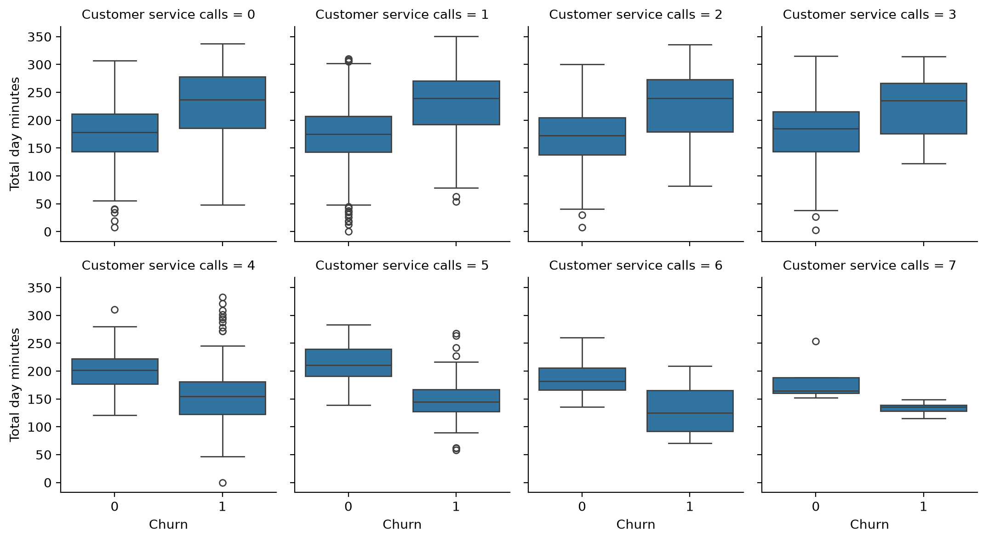

In [35]:
sns.catplot(
    x="Churn",
    y="Total day minutes",
    col="Customer service calls",
    data=df[df["Customer service calls"]<8],
    kind="box",
    col_wrap=4,
    height=3,
    aspect=0.9,
);

<Axes: xlabel='Customer service calls', ylabel='count'>

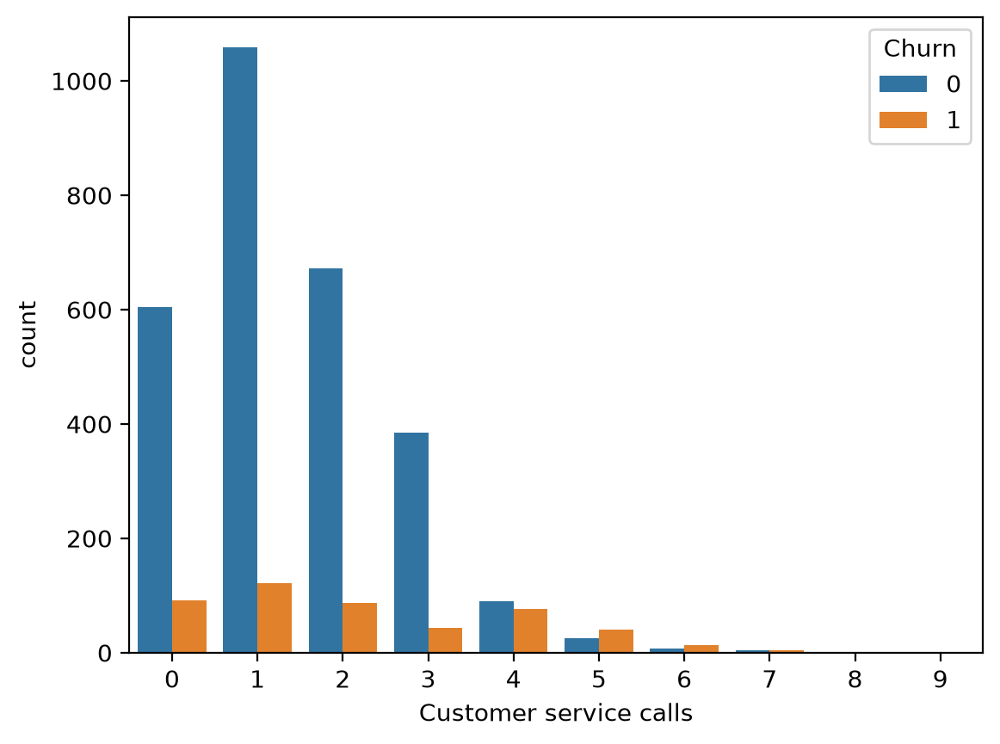

In [36]:
sns.countplot(x="Customer service calls",hue="Churn",data=df)

In [37]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   State                   3333 non-null   str           
 1   Account length          3333 non-null   int64         
 2   Area code               3333 non-null   int64         
 3   International plan      3333 non-null   str           
 4   Voice mail plan         3333 non-null   str           
 5   Number vmail messages   3333 non-null   int64         
 6   Total day minutes       3333 non-null   float64       
 7   Total day calls         3333 non-null   int64         
 8   Total day charge        3333 non-null   float64       
 9   Total eve minutes       3333 non-null   float64       
 10  Total eve calls         3333 non-null   int64         
 11  Total eve charge        3333 non-null   float64       
 12  Total night minutes     3333 non-null   float64       
 13 

<Axes: xlabel='Voice mail plan', ylabel='count'>

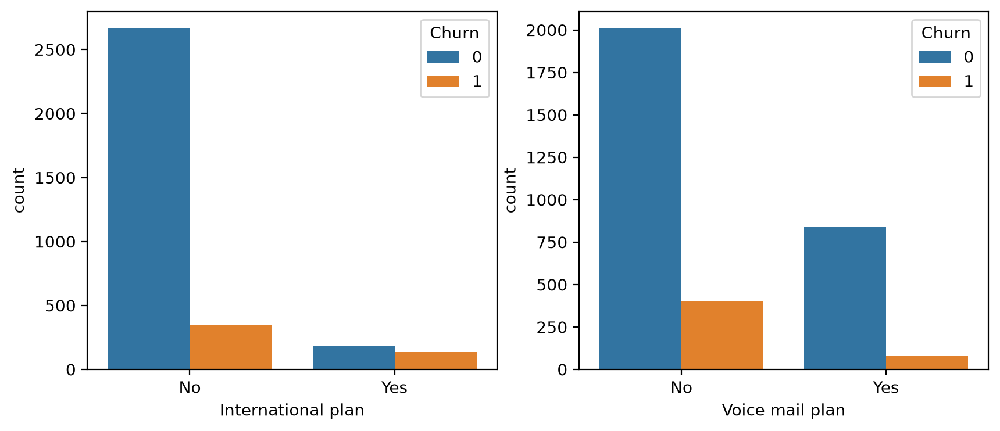

In [38]:
_,axes = plt.subplots(1,2,sharex=True,figsize=(10,4))

sns.countplot(x="International plan",hue="Churn",data=df,ax=axes[0])
sns.countplot(x="Voice mail plan",hue="Churn",data=df,ax=axes[1])

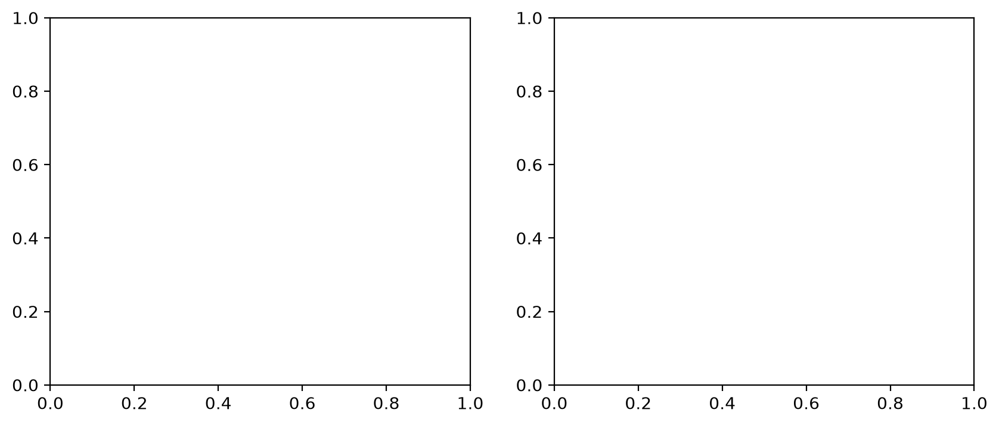

In [39]:
_,axes = plt.subplots(1,2,sharex=False,figsize=(10,4))

In [40]:
pd.crosstab(df["State"],df["Churn"]).T.sort_values(by="Churn",ascending=False)

State,AK,AL,AR,AZ,CA,CO,CT,DC,DE,FL,...,SD,TN,TX,UT,VA,VT,WA,WI,WV,WY
Churn,,,,,,,,,,,,,,,,,,,,,
1,3,8,11,4,9,9,12,5,9,8,...,8,5,18,10,5,8,14,7,10,9
0,49,72,44,60,25,57,62,49,52,55,...,52,48,54,62,72,65,52,71,96,68


In [41]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

In [42]:
df

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,0
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3328,AZ,192,415,No,Yes,36,156.2,77,26.55,215.5,126,18.32,279.1,83,12.56,9.9,6,2.67,2,0
3329,WV,68,415,No,No,0,231.1,57,39.29,153.4,55,13.04,191.3,123,8.61,9.6,4,2.59,3,0
3330,RI,28,510,No,No,0,180.8,109,30.74,288.8,58,24.55,191.9,91,8.64,14.1,6,3.81,2,0
3331,CT,184,510,Yes,No,0,213.8,105,36.35,159.6,84,13.57,139.2,137,6.26,5.0,10,1.35,2,0


In [43]:
X = df.drop(["Churn","State"], axis=1)
X["International plan"] = X["International plan"].map({"Yes":1,"No":0})
X["Voice mail plan"] = X["Voice mail plan"].map({"Yes":1,"No":0})

In [44]:
scaler = StandardScaler()
X_scales = scaler.fit_transform(X)

In [45]:
%%time
tsne = TSNE(random_state=17)
tsne_repr = tsne.fit_transform(X_scales)

CPU times: user 14.4 s, sys: 1.2 s, total: 15.6 s
Wall time: 3.58 s


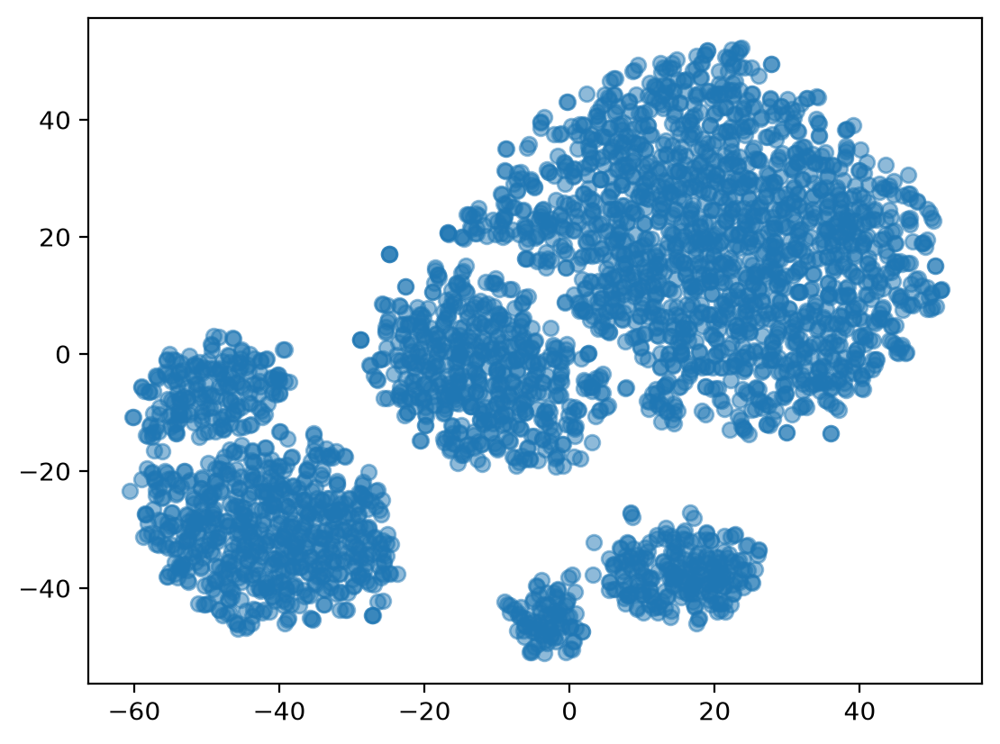

In [46]:
plt.scatter(tsne_repr[:,0],tsne_repr[:,1],alpha=0.5)

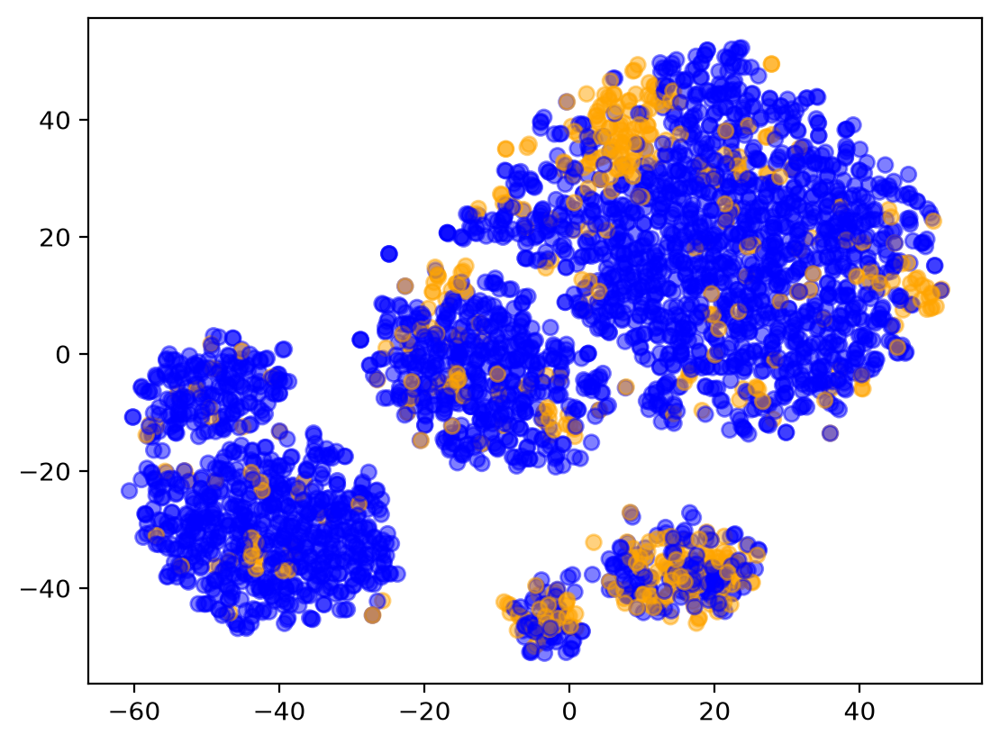

In [50]:
plt.scatter(
    tsne_repr[:,0],
    tsne_repr[:,1],
    c=df["Churn"].map({0:"blue",1:'orange'}),
    alpha=0.5
)